# Chương 3 — Ứng dụng 1: Phân tích Giỏ hàng (Market Basket Analysis)

**Thuật toán sử dụng:** **Optimized CHARM** (`CharmMining.jl`, tự cài đặt từ đầu bằng Julia — Chương 1) kết hợp bộ sinh luật kết hợp dựa trên **bao đóng Galois (`ClosureSupportIndex`)** (`src/rules.jl`).

**Tập dữ liệu:** [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail) (giao dịch bán lẻ trực tuyến tại Vương quốc Anh, 12/2010 – 12/2011, 541.909 dòng hóa đơn).

### Thiết kế biến đổi dữ liệu & Độ phù hợp với thuật toán CHARM
- Mỗi hóa đơn (`InvoiceNo`) sau khi loại bỏ đơn hủy, số lượng/giá âm và các mã phí dịch vụ (`POST`, `DOT`, `M`, `C2`, `CRUK`, `AMAZONFEE`, `GIFT_*`, ...) được gom thành một giao dịch gồm tập các mã sản phẩm (`StockCode`, chuẩn hóa viết hoa) duy nhất.
- Dữ liệu bán lẻ trực tuyến có đặc tính **rất thưa (sparse)** (3.787 SKU, mật độ ma trận **0.691%**), chứa nhiều cụm sản phẩm mua kèm chặt chẽ như bộ nhãn thảo mộc **Herb Marker**, bộ đĩa trà **Regency Tea Plate**, đồ trang trí Giáng sinh bằng gỗ, và nhà búp bê **Poppy's Playhouse**.
- Thuật toán **Optimized CHARM** biểu diễn `Tidset` bằng mảng bit liền kề (`BitVector`, 309 từ 64-bit ≈ 2.47 KB/item) cùng phép giao `@inbounds @simd`, chỉ mất trung vị **74.16 ms** tại `minsup = 1.0%`. Bộ sinh luật (`src/rules.jl`) tra cứu chính xác support của mọi tập con qua `ClosureSupportIndex` và sinh toàn bộ các luật có hợp $A \cup B$ là tập đóng (trên dữ liệu này tại `minsup = 1.0%`, cả 2.026 tập phổ biến đều tự đóng nên tập luật thu được trùng khớp 100% với toàn bộ tập luật phổ biến).

## 1. Thiết lập môi trường (Google Colab / Local)
Ô dưới đây tự động cài đặt Julia (nếu đang chạy trên Google Colab chưa có sẵn Julia) và xác định thư mục gốc của repository.

In [1]:
import os, shutil, subprocess
from pathlib import Path

# Cài đặt Julia trên Google Colab nếu chưa có
if shutil.which("julia") is None:
    print("Installing Julia 1.11.4 for Google Colab...")
    subprocess.run(
        "curl -fsSL https://julialang-s3.julialang.org/bin/linux/x64/1.11/julia-1.11.4-linux-x86_64.tar.gz -o julia.tar.gz "
        "&& tar -xzf julia.tar.gz -C /usr --strip-components 1",
        shell=True, check=True,
    )

print(subprocess.check_output(["julia", "--version"], text=True).strip())

# Đảm bảo thư mục làm việc là repo root
cwd = Path.cwd()
if (cwd / "src" / "CharmMining.jl").exists():
    REPO_ROOT = cwd
elif (cwd.parent / "src" / "CharmMining.jl").exists():
    REPO_ROOT = cwd.parent
    os.chdir(REPO_ROOT)
else:
    raise FileNotFoundError(
        "Không tìm thấy src/CharmMining.jl. Trên Google Colab, hãy git clone repo trước rồi cd vào thư mục repo."
    )

print("Working directory:", REPO_ROOT)

julia version 1.13.3
Working directory: C:\Users\maduc\frequent-itemset-mining


## 2. Tải, làm sạch và chuyển đổi dữ liệu sang định dạng SPMF
Script `applications/market_basket/prepare_data.py` thực hiện:
1. Tải bộ dữ liệu **UCI Online Retail** (nếu chưa có sẵn cục bộ).
2. Loại bỏ bản ghi thiếu `InvoiceNo`/`StockCode`/`Description`, đơn hủy (`InvoiceNo` bắt đầu bằng `'C'`), `Quantity <= 0`, `UnitPrice <= 0`, và các mã phí dịch vụ không phải hàng hóa (`POST`, `DOT`, `M`, `BANK CHARGES`, ...).
3. Chuẩn hóa tên sản phẩm theo `StockCode`, gán `item_id` nguyên liên tục `1..M` tất định.
4. Gom theo `InvoiceNo` và xuất `data/applications/online_retail/transactions.txt` (chuẩn SPMF) cùng từ điển `item_mapping.csv`.

In [2]:
import json
import pandas as pd

subprocess.run(["python", "applications/market_basket/prepare_data.py"], check=True)

with open("results/app1/dataset_summary.json", encoding="utf-8") as f:
    summary = json.load(f)

summary_rows = [
    ("Số dòng hóa đơn gốc (Raw rows)", f"{summary['raw_rows']:,}"),
    ("Loại bỏ thiếu InvoiceNo/StockCode/Description", f"{summary['dropped_missing_fields']:,}"),
    ("Loại bỏ đơn hàng bị hủy (InvoiceNo bắt đầu bằng 'C')", f"{summary['dropped_canceled_invoices']:,}"),
    ("Loại bỏ Quantity <= 0 hoặc UnitPrice <= 0", f"{summary['dropped_non_positive_qty_or_price']:,}"),
    ("Loại bỏ mã phí dịch vụ / không phải hàng hóa", f"{summary['dropped_non_product_items']:,}"),
    ("Số dòng sạch còn lại (Clean rows)", f"{summary['clean_rows']:,}"),
    ("Số giao dịch / hóa đơn (|D|)", f"{summary['n_transactions']:,}"),
    ("Số giao dịch có >= 2 sản phẩm", f"{summary['n_multi_item_transactions']:,}"),
    ("Số sản phẩm duy nhất (|I|)", f"{summary['n_unique_items']:,}"),
    ("Kích thước giỏ hàng (TB / Trung vị / Tối đa)", f"{summary['avg_basket_size']} / {summary['median_basket_size']} / {summary['max_basket_size']}"),
    ("Mật độ ma trận giao dịch", f"{summary['matrix_density'] * 100:.3f}%"),
]
display(pd.DataFrame(summary_rows, columns=["Chỉ số", "Giá trị"]))

,Chỉ số,Giá trị
0,Số dòng hóa đơn gốc (Raw rows),"541,909"
1,Loại bỏ thiếu InvoiceNo/StockCode/Description,"1,454"
2,Loại bỏ đơn hàng bị hủy (InvoiceNo bắt đầu bằn...,"9,288"
3,Loại bỏ Quantity <= 0 hoặc UnitPrice <= 0,"1,063"
4,Loại bỏ mã phí dịch vụ / không phải hàng hóa,"2,536"
5,Số dòng sạch còn lại (Clean rows),"527,568"
6,Số giao dịch / hóa đơn (|D|),"19,773"
7,Số giao dịch có >= 2 sản phẩm,"18,267"
8,Số sản phẩm duy nhất (|I|),"3,787"
9,Kích thước giỏ hàng (TB / Trung vị / Tối đa),26.15 / 15 / 1105


## 3. Khai thác Tập phổ biến đóng & Sinh Luật kết hợp bằng `CharmMining.jl`
Toàn bộ kết quả được tạo trực tiếp bởi cài đặt **Optimized CHARM (`mine_file_bit`)** và module sinh luật kết hợp theo bao đóng (`generate_rules`, `top_rules_by_lift`) trong `src/rules.jl` — **không sử dụng bất kỳ thư viện FIM bên ngoài nào**.

In [3]:
subprocess.run(["julia", "--project=.", "applications/market_basket/run_mba.jl"], check=True)

CompletedProcess(args=['julia', '--project=.', 'applications/market_basket/run_mba.jl'], returncode=0)

## 4. Phân tích kết quả: Độ nhạy theo `minsup` & Top-10 Luật kết hợp theo Lift

In [4]:
sens_df = pd.read_csv("results/app1/minsup_sensitivity.csv")
print("=== Bảng độ nhạy theo ngưỡng minsup ===")
display(sens_df)

top10_df = pd.read_csv("results/app1/top10_rules_lift_dedup.csv")
print("\n=== Top-10 Luật kết hợp theo Lift (minsup = 1.0%, minconf = 50%, đã khử cặp đối xứng) ===")
display(top10_df[["rank", "antecedent_names", "consequent_names", "support_count", "support_pct", "confidence_pct", "lift", "leverage"]])

=== Bảng độ nhạy theo ngưỡng minsup (trung vị 5 lần chạy, đối chiếu Closed vs All FI) ===


minsup_pct,minsup_count,num_closed_itemsets,num_all_frequent_itemsets,compression_ratio,num_closed_len2plus,max_itemset_len,num_rules_conf50,runtime_ms
5.0,989,36,36,1.0,0,1,0,0.110
3.0,594,143,143,1.0,10,2,14,1.412
2.5,495,234,234,1.0,43,3,40,2.851
2.0,396,395,395,1.0,93,3,61,8.201
1.5,297,763,763,1.0,282,4,215,23.860
1.0,198,2026,2026,1.0,1197,5,962,74.158
0.8,159,3804,3804,1.0,2772,5,2882,114.515



=== Top-10 Luật kết hợp theo Lift (minsup = 1.0%, minconf = 50%, đã khử cặp đối xứng) ===


rank,antecedent_names,consequent_names,support_count,support_pct,confidence_pct,lift,leverage
1,HERB MARKER ROSEMARY + HERB MARKER PARSLEY,HERB MARKER THYME,203,1.0267,94.42,78.7738,0.010136
2,HERB MARKER THYME + HERB MARKER PARSLEY,HERB MARKER ROSEMARY,203,1.0267,95.31,78.5195,0.010136
3,HERB MARKER THYME + HERB MARKER BASIL,HERB MARKER ROSEMARY,200,1.0115,95.24,78.4643,0.009986
4,HERB MARKER ROSEMARY + HERB MARKER BASIL,HERB MARKER THYME,200,1.0115,93.46,77.9723,0.009985
5,HERB MARKER THYME,HERB MARKER ROSEMARY,221,1.1177,93.25,76.8255,0.011031
6,HERB MARKER THYME + HERB MARKER ROSEMARY,HERB MARKER PARSLEY,203,1.0267,91.86,76.3131,0.010132
7,HERB MARKER THYME,HERB MARKER PARSLEY,213,1.0772,89.87,74.6667,0.010628
8,HERB MARKER PARSLEY,HERB MARKER ROSEMARY,215,1.0873,90.34,74.4257,0.010727
9,HERB MARKER THYME + HERB MARKER ROSEMARY,HERB MARKER BASIL,200,1.0115,90.50,73.9426,0.009978
10,HERB MARKER PARSLEY,HERB MARKER MINT,212,1.0722,89.08,73.3872,0.010576


## 5. Trực quan hóa kết quả

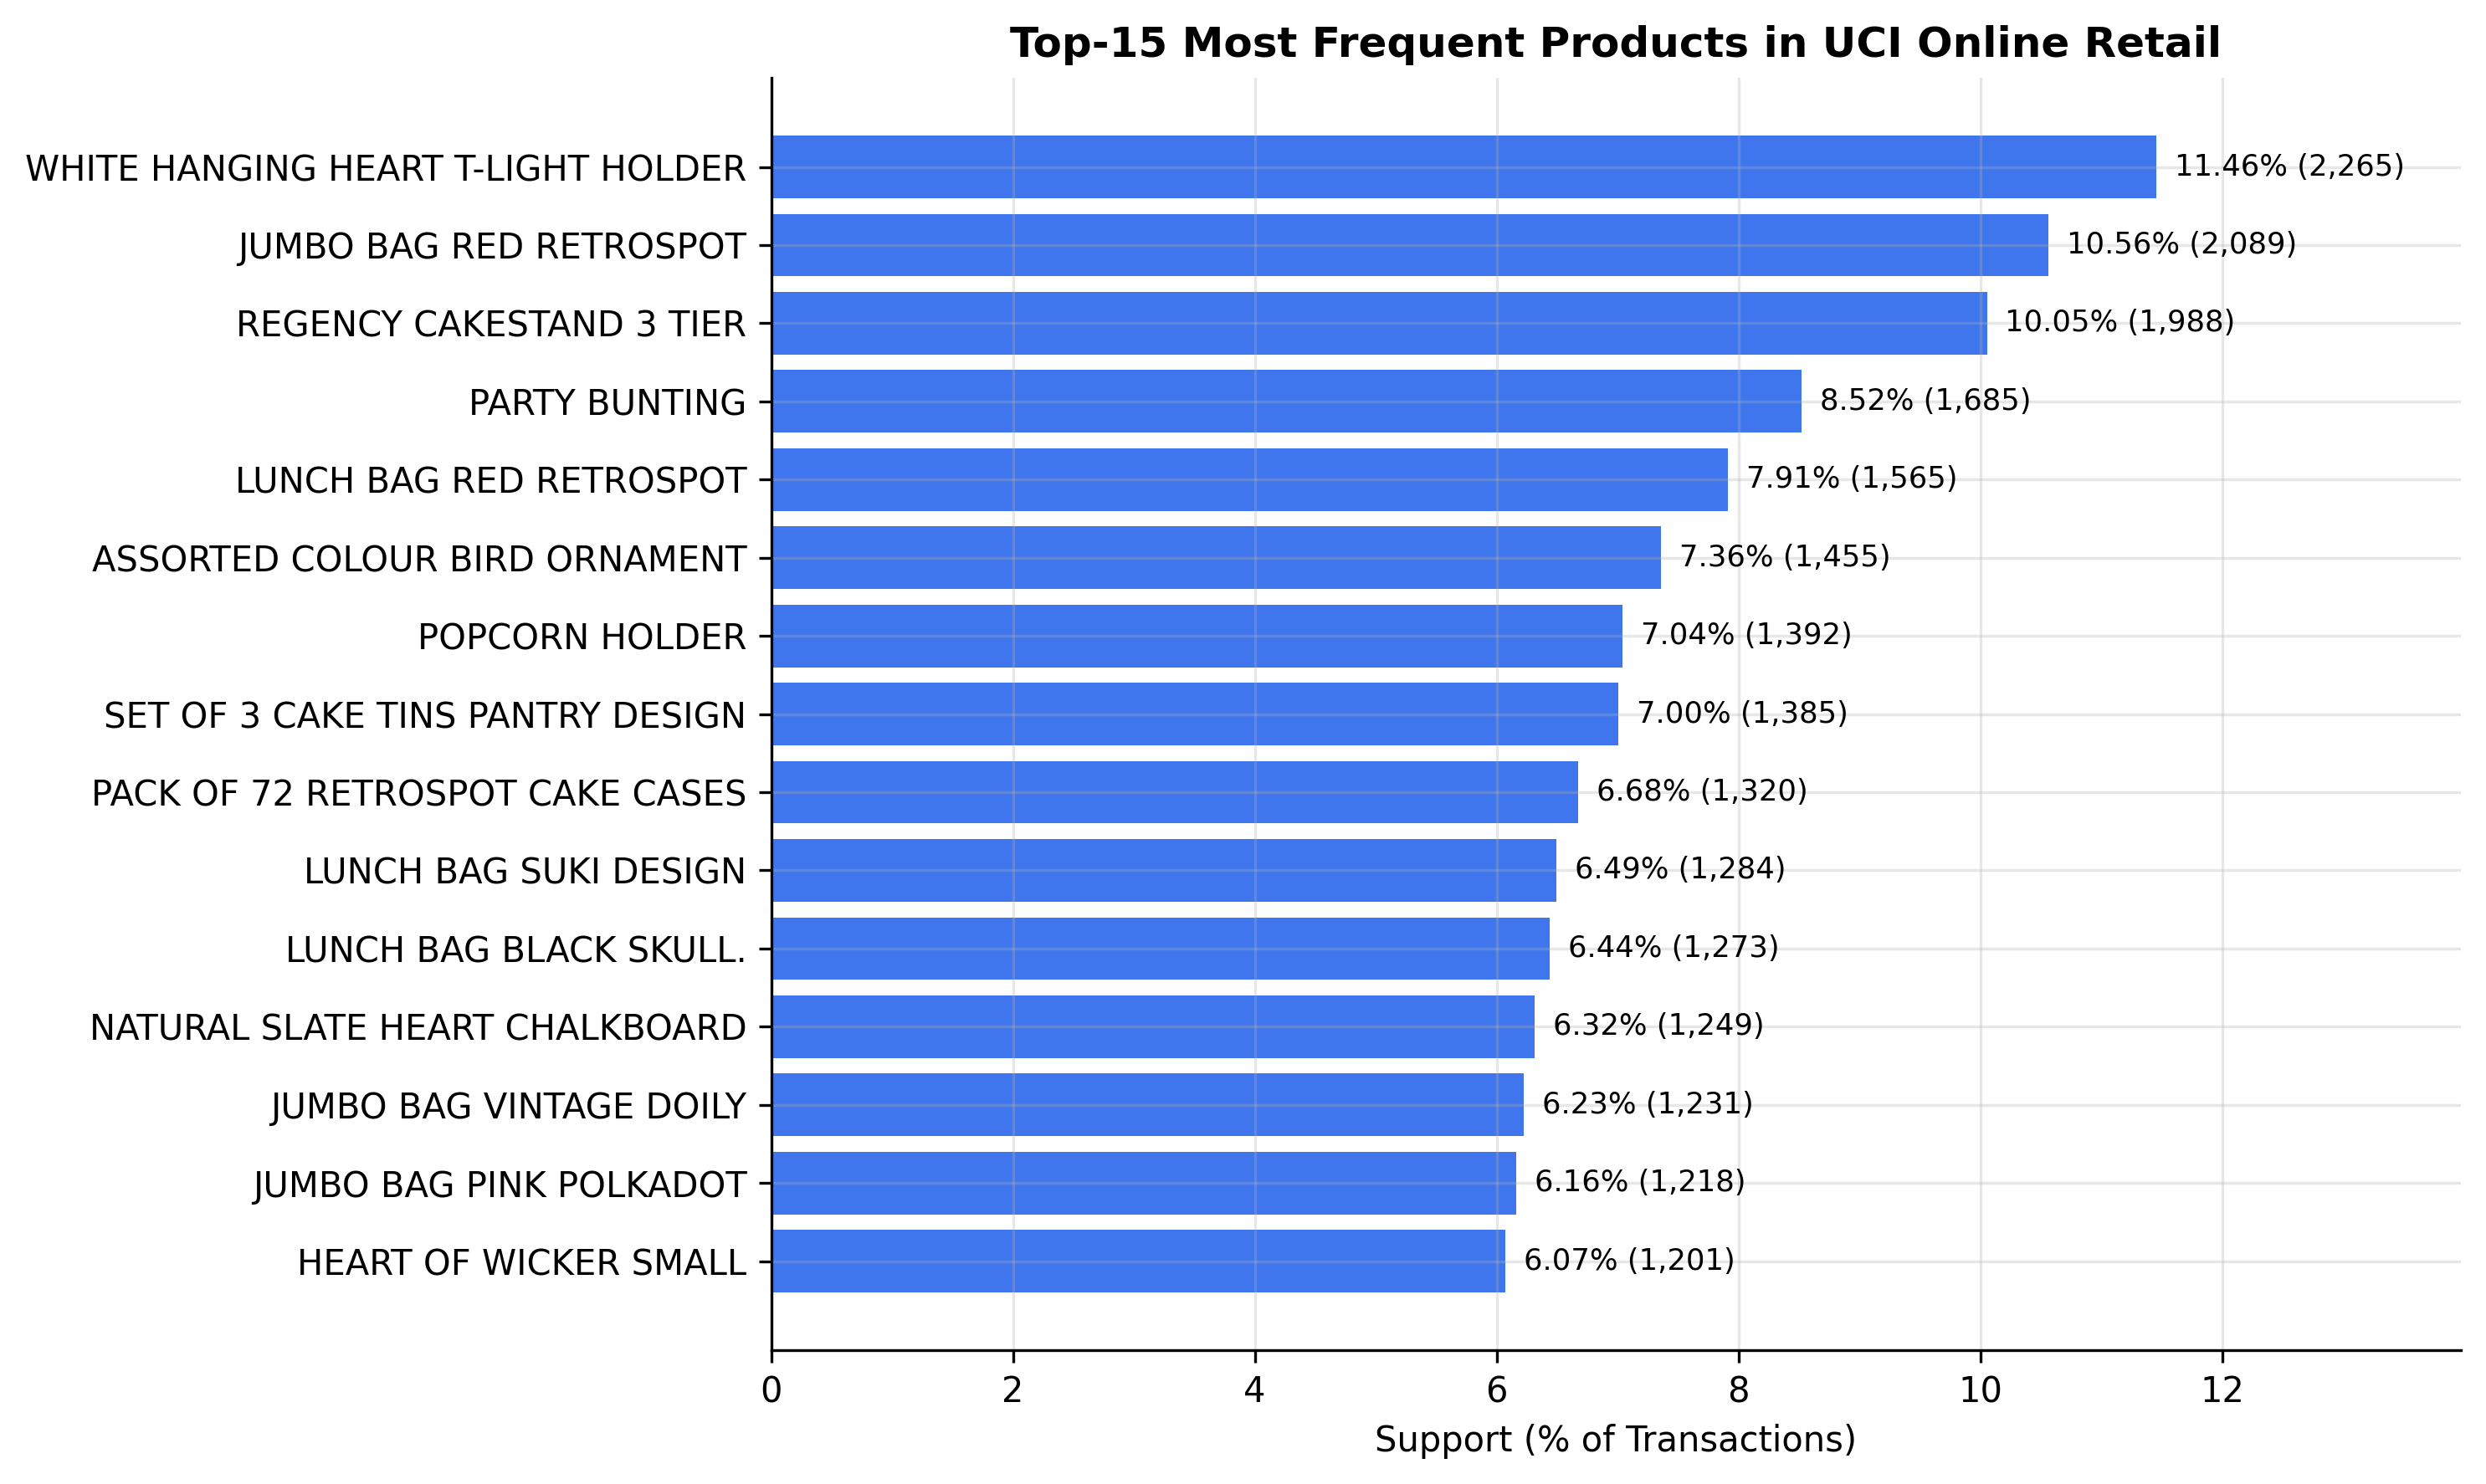

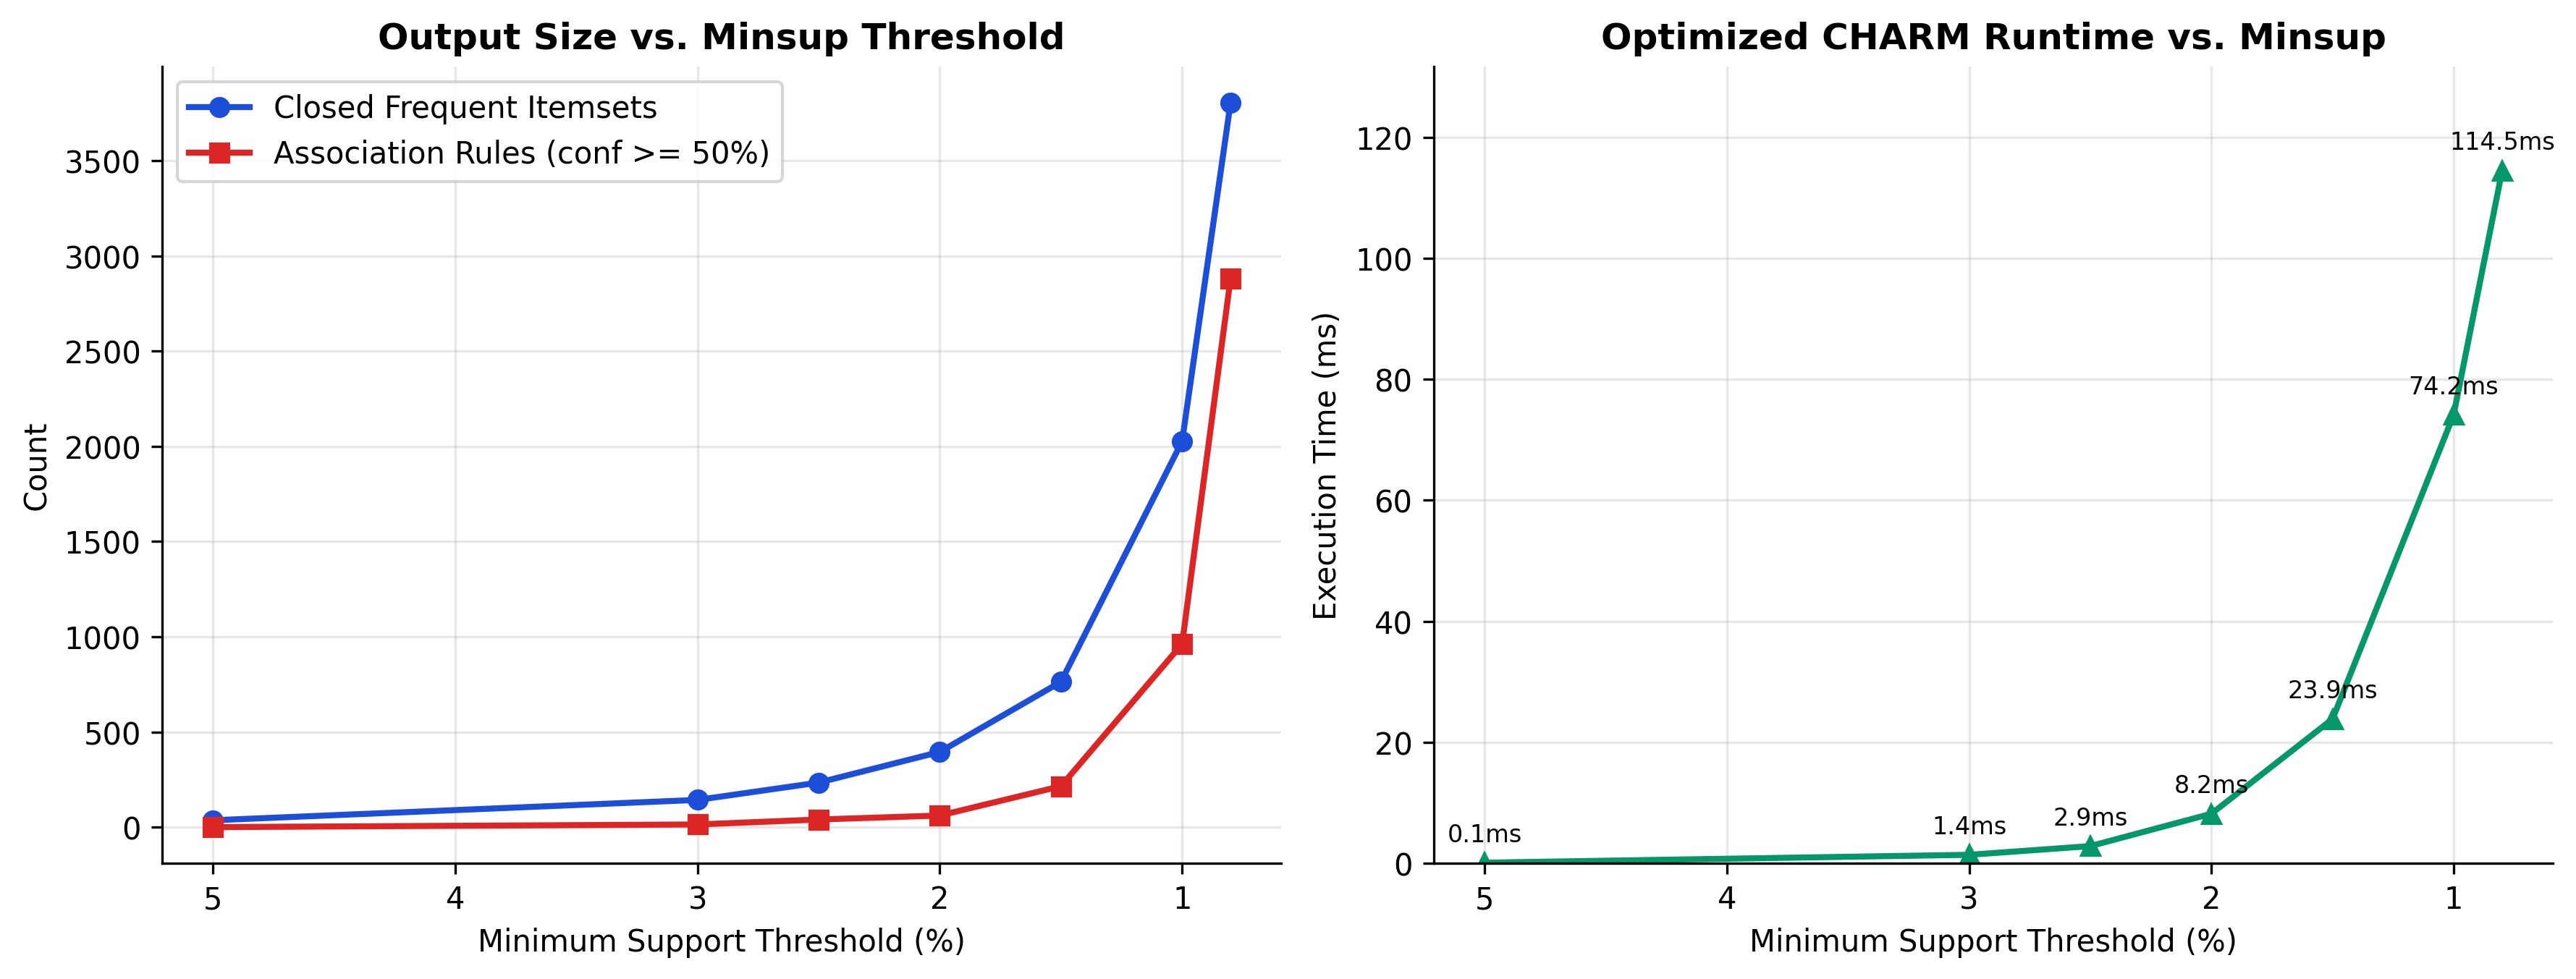

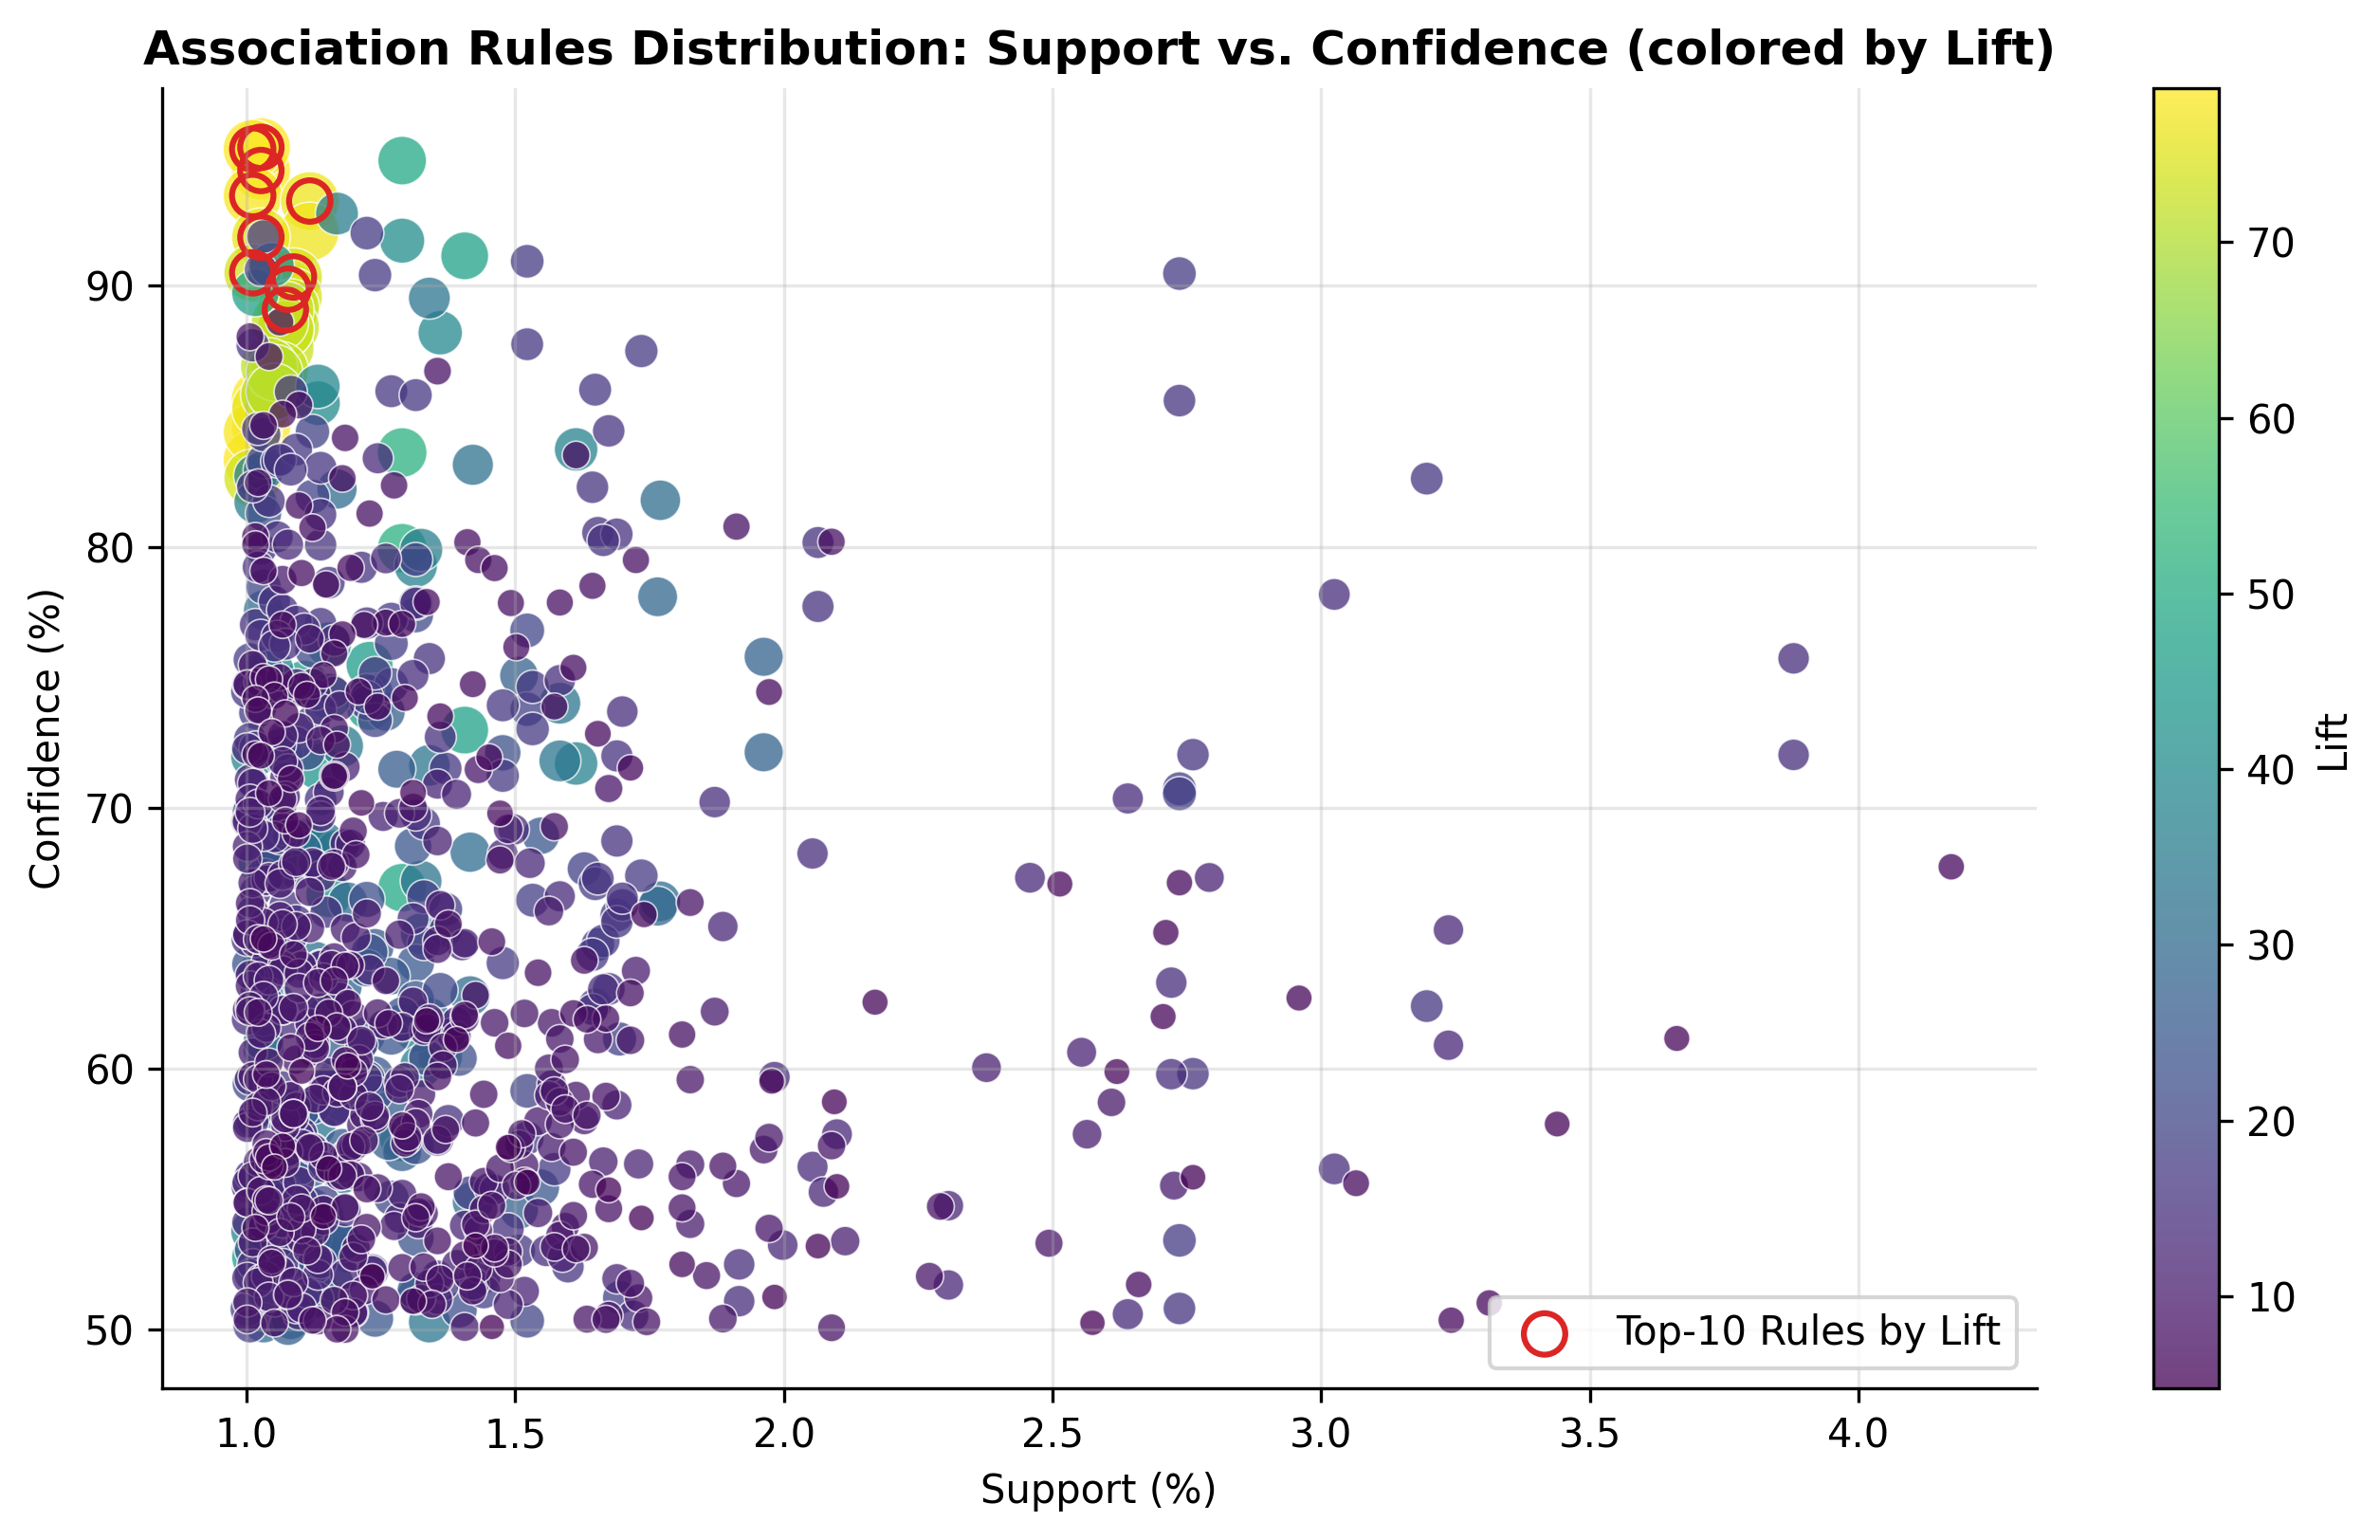

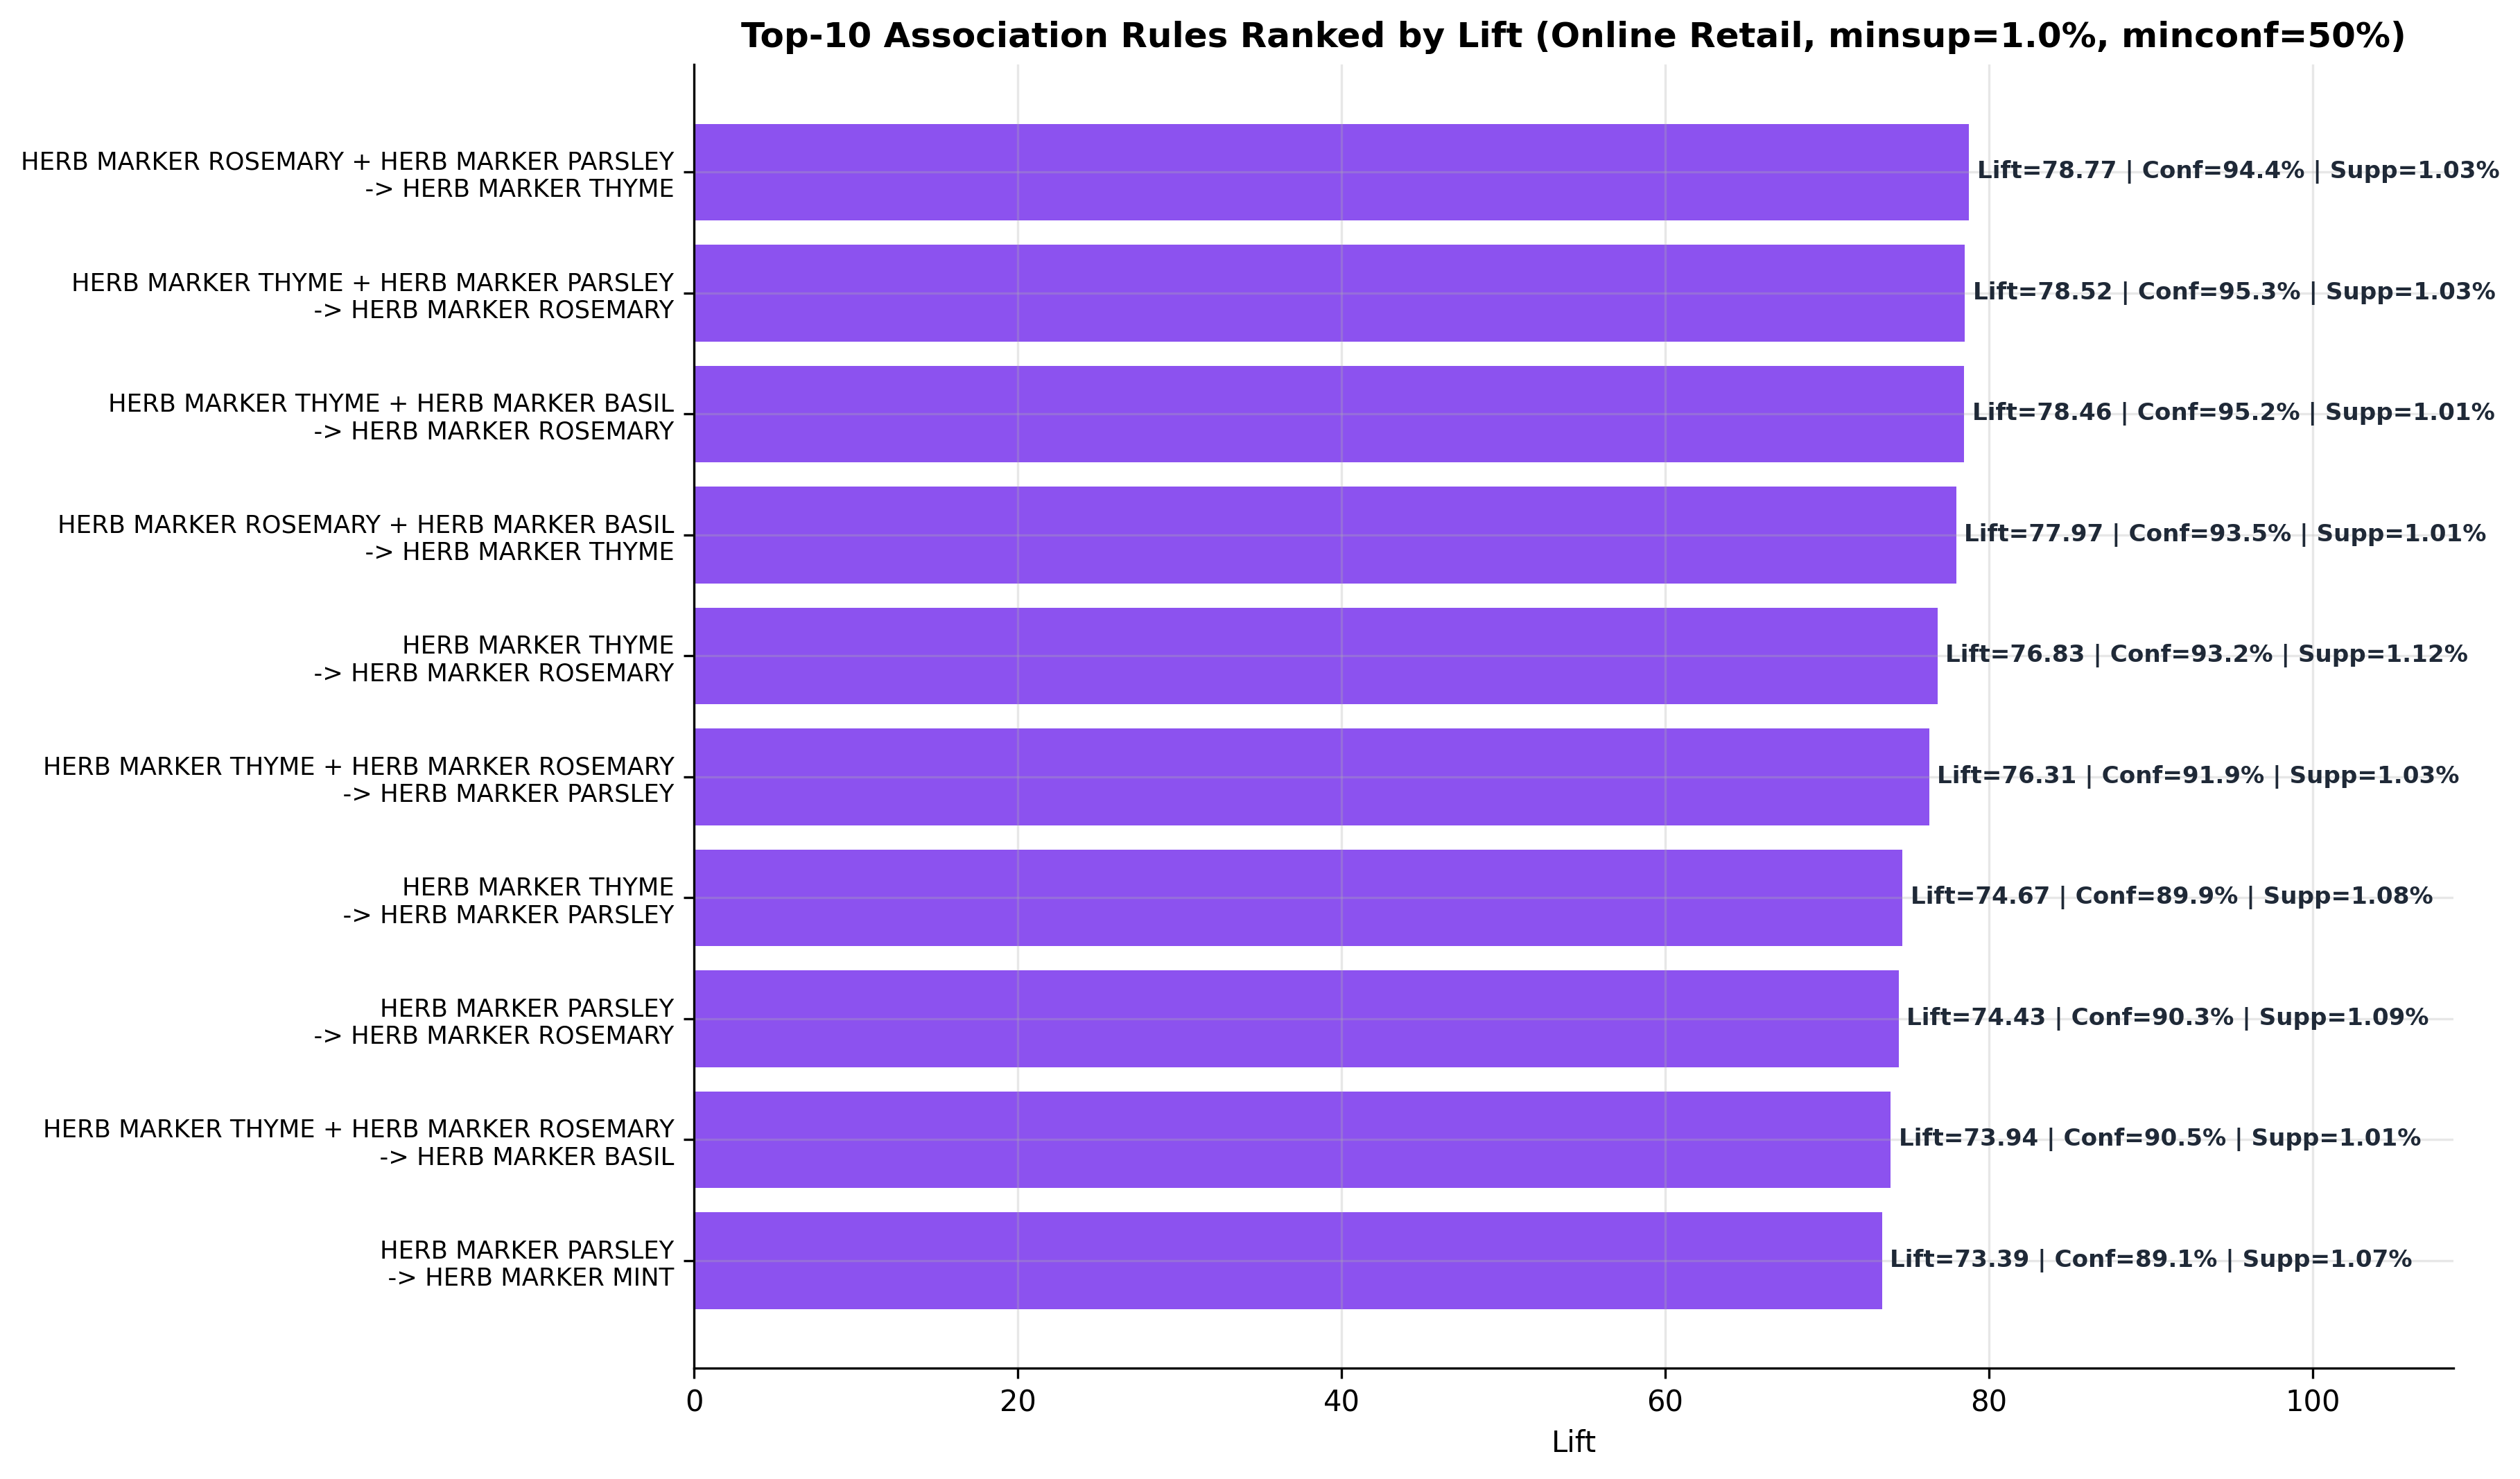

In [5]:
from IPython.display import Image, display as ipy_display

subprocess.run(["python", "applications/market_basket/plot_mba.py"], check=True)

for fig_name in [
    "fig1_top15_products.png",
    "fig2_minsup_sensitivity.png",
    "fig3_rules_scatter.png",
    "fig4_top10_lift.png",
]:
    ipy_display(Image(filename=f"results/app1/figures/{fig_name}"))

## 6. Kiểm chứng hậu kiểm (Post-hoc Verification)
Tái lập toàn bộ các kiểm tra hậu kiểm: phân bố bộ 6 nhãn **Herb Marker** (gồm `CHIVES`), tỷ lệ nền mùa vụ tháng 10–12/2011 & **Lift tính riêng trong mùa**, và độ đa dạng `CustomerID`.

In [6]:
subprocess.run(["python", "applications/market_basket/posthoc_analysis.py"], check=True)

with open("results/app1/posthoc_verification.json", encoding="utf-8") as f:
    ph = json.load(f)

print("=== 1. Phân bố số nhãn Herb Marker trong 289 hóa đơn có mua dòng này ===")
herb_dist_df = pd.DataFrame([
    {"Số nhãn Herb Marker trong giỏ": int(k), "Số hóa đơn": v,
     "Tỷ lệ trong 289 giỏ Herb (%)": round(100.0 * v / ph["herb_marker_analysis"]["baskets_with_at_least_1_herb"], 2)}
    for k, v in ph["herb_marker_analysis"]["size_distribution_among_herb_baskets"].items()
])
display(herb_dist_df)

print("\n=== 2. Kiểm chứng mức tập trung tháng 10–12/2011 (so với mốc nền sau ngày ra mắt 2011-06-09: 49.70%) ===")
season_df = pd.DataFrame([
    {"Sản phẩm": v["description"], "Ngày bán đầu tiên": v["first_invoice_date"],
     "Mốc nền 10–12/2011 sau ra mắt (%)": v["post_launch_baseline_oct_dec_2011_pct"],
     "HĐ 10–12/2011": v["oct_dec_2011_invoices"], "Tỷ lệ 10–12/2011 (%)": v["oct_dec_2011_pct"]}
    for v in ph["seasonality_analysis"]["wooden_decorations"].values()
])
display(season_df)
print("Lift trong giai đoạn 10–12/2011 (N=5,572):", ph["seasonality_analysis"]["in_season_oct_dec_2011_rules"])
print("Bộ 3 {TREE, STOCKING, SLEIGH}:", ph["seasonality_analysis"]["wooden_3_item_tree_stocking_sleigh"])

print("\n=== 3. Độ đa dạng khách hàng (CustomerID duy nhất) ===")
cust_df = pd.DataFrame([
    {"Cụm sản phẩm": k, "Tổng HĐ": v["invoices"], "HĐ có CustomerID": v["invoices_with_customer_id"], "Khách hàng duy nhất": v["unique_customers"]}
    for k, v in ph["customer_diversity"].items()
])
display(cust_df)

=== 1. Phân bố số nhãn Herb Marker trong 289 hóa đơn có mua dòng này ===


Số nhãn Herb Marker trong giỏ,Số hóa đơn,Tỷ lệ trong 289 giỏ Herb (%)
1,18,6.23
2,16,5.54
3,19,6.57
4,38,13.15
5,41,14.19
6,157,54.33



=== 2. Kiểm chứng mức tập trung tháng 10–12/2011 (so với mốc nền sau ngày ra mắt 2011-06-09: 49.70%) ===


Sản phẩm,Ngày bán đầu tiên,Mốc nền 10–12/2011 sau ra mắt (%),HĐ 10–12/2011,Tỷ lệ 10–12/2011 (%)
SET OF 3 WOODEN TREE DECORATIONS,2011-06-09,49.7,217,74.06
SET OF 3 WOODEN STOCKING DECORATION,2011-06-09,49.7,237,74.29
SET OF 3 WOODEN SLEIGH DECORATIONS,2011-06-09,49.7,228,76.25


Lift trong giai đoạn 10–12/2011 (N=5,572): {'tree_to_stocking': {'in_season_invoices_n': 5572, 'support_count': 172, 'support_pct': 3.09, 'confidence_pct': 79.26, 'lift_in_season': 18.64}, 'sleigh_to_stocking': {'in_season_invoices_n': 5572, 'support_count': 158, 'support_pct': 2.84, 'confidence_pct': 69.3, 'lift_in_season': 16.29}}
Bộ 3 {TREE, STOCKING, SLEIGH}: {'invoices': 159, 'support_pct': 0.8041, 'conf_given_tree_and_stocking_pct': 72.6}

=== 3. Độ đa dạng khách hàng (CustomerID duy nhất) ===


Cụm sản phẩm,Tổng HĐ,HĐ có CustomerID,Khách hàng duy nhất
herb_thyme_rosemary_parsley,203,164,116
wooden_tree_stocking,219,182,132
dolly_girl_spaceboy_cutlery,228,214,165
regency_sugar_milk,243,206,162


## 7. Diễn giải ý nghĩa kinh doanh & Khuyến nghị thực tiễn

Từ **962 luật kết hợp** khai thác bằng **Optimized CHARM (`CharmMining.jl`)** tại `minsup = 1.0%`, `minconf = 50%` và số liệu hậu kiểm (`posthoc_verification.json`), nhóm rút ra 4 nhận định nhất quán:

1. **Hành vi mua theo bộ sưu tập & bảo vệ biên lợi nhuận:** 6 luật có vế trái 2 nhãn trong Top-10 đạt xác suất mua thêm nhãn thứ 3 là **90.50% – 95.31%** (Lift `73.94 – 78.77`). Trong 289 giỏ mua dòng Herb Marker (6 SKU gồm cả `CHIVES`), **54.3% (`157/289`)** đã mua đủ cả 6 nhãn và **45.7% (`132/289`)** dừng ở 1–5 nhãn. Không nên giảm giá đại trà (gây giảm biên lợi nhuận); ưu tiên nút UX *"Thêm các nhãn còn thiếu"* và gợi ý nhắm riêng vào nhóm 45.7% giỏ chưa đủ bộ.
2. **Liên kết khác công năng trong cùng dòng thiết kế:** `REGENCY SUGAR BOWL GREEN => REGENCY MILK JUG PINK` (tần suất mua kèm lịch sử **75.5%**, Lift `45.36`) và `GARAGE KEY FOB => KEY FOB , SHED` (**71.9%**, Lift `38.24`) phù hợp hiển thị chéo trong mục *"Sản phẩm cùng bộ sưu tập"*.
3. **Cụm trang trí Giáng sinh tập trung ở mức ~1.5× vào tháng 10–12/2011 (một mùa quan sát được):** Cả 3 mã gỗ có ngày bán đầu tiên **2011-06-09**; tỷ lệ hóa đơn tháng 10–12/2011 đạt `74.06% – 76.25%` so với mốc nền sau ra mắt **49.70%** (tính trên toàn bộ hóa đơn cửa hàng từ 2011-06-09, tức gấp `1.49× – 1.53×`, còn ~24–26% diễn ra ở 06–09/2011). Lift tính riêng trong tháng 10–12/2011 là `18.64` và `16.29` (thấp hơn `46.33`/`42.08` do mẫu số 13 tháng gồm cả các tháng ngoài mùa và trước khi mã ra mắt). Bộ 3 `{TREE, STOCKING, SLEIGH}` đạt `159` HĐ (`0.80%`, dưới ngưỡng `1.0%`, `Conf({TREE, STOCKING} => SLEIGH) = 72.60%`). Nhất quán với mục 1: ưu tiên trưng bày theo chủ đề & gợi ý chéo thay vì giảm giá trực tiếp.
4. **Đồng bộ tồn kho & gợi ý chéo cặp đối xứng (*Dolly Girl* & *Spaceboy*):** `CHILDRENS CUTLERY DOLLY GIRL => SPACEBOY` (**76.2%**, Lift `40.97`, 228 HĐ trên **165 khách hàng duy nhất**) gợi ý hiển thị chéo hai mẫu và đồng bộ kế hoạch tồn kho thay vì suy diễn quá mức về nhân khẩu học.

Xem báo cáo chi tiết đầy đủ tại [`docs/app1_market_basket.md`](../docs/app1_market_basket.md).